# Softmax Regression — Multiclass Logistic Regression

## 1. Definition and intuition
Softmax regression extends logistic regression to K classes. A linear score is computed for each class, then softmax converts those scores into probabilities that sum to one. It is a linear decision-boundary model, not a neural network with hidden layers.

## 2. Mathematics
For features $x_i\in\mathbb{R}^d$, weights $W\in\mathbb{R}^{d\times K}$ and biases $b\in\mathbb{R}^K$,

$$
z_i=x_i^T W+b,\qquad p_{ik}=\frac{e^{z_{ik}}}{\sum_{j=1}^{K}e^{z_{ij}}}.
$$

The average cross-entropy loss is

$$
L(W,b)=-\frac1n\sum_i\log p_{i,y_i}+\frac{\lambda}{2}\|W\|_F^2.
$$

The gradients are $\nabla_W L=X^T(P-Y)/n+\lambda W$ and $\nabla_b L=\sum_i(P_i-Y_i)/n$, where Y is one-hot encoded. The bias is not penalized.

## 3. Why it works and assumptions
Cross-entropy is the negative log-likelihood of the categorical model. For a linear score model, it is convex in W and b; adding L2 regularization helps control large weights. Optimization finds a global minimum up to numerical convergence, but the model can still underfit nonlinear class boundaries.

Assumptions are not that the raw features are normally distributed. Rather, the model assumes class log-odds are linear functions of the features. Important failure modes include nonlinear separations, severe class imbalance, and poorly scaled features.

## 4. Dataset and preprocessing

We use a reproducible three-class dataset, split before scaling. The scratch implementation trains full-batch gradient descent; scikit-learn provides a mature optimized implementation.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
X, y = make_classification(
    n_samples=1200, n_features=15, n_informative=10, n_redundant=3,
    n_classes=3, n_clusters_per_class=1, class_sep=1.4,
    random_state=SEED
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
n_classes = len(np.unique(y_train))
print(X_train.shape, np.bincount(y_train))


(900, 15) [299 299 302]


## 5. Stable softmax from scratch

Subtracting the maximum logit before exponentiating does not change probabilities, because the same multiplicative factor cancels from numerator and denominator. It prevents overflow. The one-hot target matrix has shape `(n_samples, n_classes)`.

Scratch accuracy: 0.9266666666666666
Scratch log loss: 0.22181555675018544


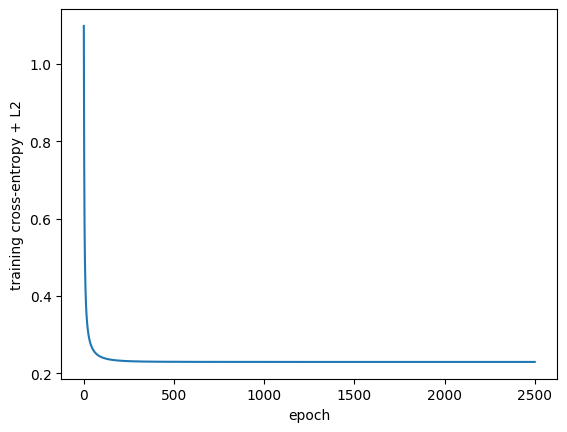

In [2]:
def softmax(logits):
    logits = np.asarray(logits, dtype=float)
    shifted = logits - logits.max(axis=1, keepdims=True)
    exp_logits = np.exp(shifted)
    return exp_logits / exp_logits.sum(axis=1, keepdims=True)

def fit_softmax_gd(X, y, learning_rate=0.15, epochs=2500, l2=0.01):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y)
    if X.ndim != 2 or y.ndim != 1 or len(X) != len(y) or len(X) == 0:
        raise ValueError("X must be non-empty 2D; y must be matching 1D")
    if learning_rate <= 0 or epochs < 1 or l2 < 0:
        raise ValueError("Invalid hyperparameters")
    classes = np.unique(y)
    if not np.array_equal(classes, np.arange(len(classes))):
        raise ValueError("Labels must be encoded as 0, 1, ..., K-1")
    n, d = X.shape
    k = len(classes)
    Y = np.eye(k)[y.astype(int)]
    W = np.zeros((d, k))
    b = np.zeros(k)
    losses = []
    for _ in range(epochs):
        logits = X @ W + b
        P = softmax(logits)
        loss = -np.mean(np.log(np.maximum(P[np.arange(n), y.astype(int)], 1e-15))) + 0.5*l2*np.sum(W*W)
        losses.append(loss)
        dlogits = (P - Y) / n
        grad_W = X.T @ dlogits + l2*W
        grad_b = dlogits.sum(axis=0)
        W -= learning_rate * grad_W
        b -= learning_rate * grad_b
    return W, b, losses

def predict_proba_softmax(X, W, b):
    return softmax(np.asarray(X) @ W + b)

def predict_softmax(X, W, b):
    return predict_proba_softmax(X, W, b).argmax(axis=1)

W, b, losses = fit_softmax_gd(X_train, y_train, learning_rate=0.15, epochs=2500, l2=0.01)
p_scratch = predict_proba_softmax(X_test, W, b)
y_pred_scratch = p_scratch.argmax(axis=1)
print("Scratch accuracy:", accuracy_score(y_test, y_pred_scratch))
print("Scratch log loss:", log_loss(y_test, p_scratch))
plt.plot(losses); plt.xlabel("epoch"); plt.ylabel("training cross-entropy + L2"); plt.show()


## 6. Compare with scikit-learn

The default solver and regularization scale differ from the scratch optimizer. Compare generalization metrics; do not expect identical coefficients unless the objective and regularization conventions are precisely matched.

scikit-learn accuracy: 0.9233333333333333
scikit-learn log loss: 0.2373339057720282


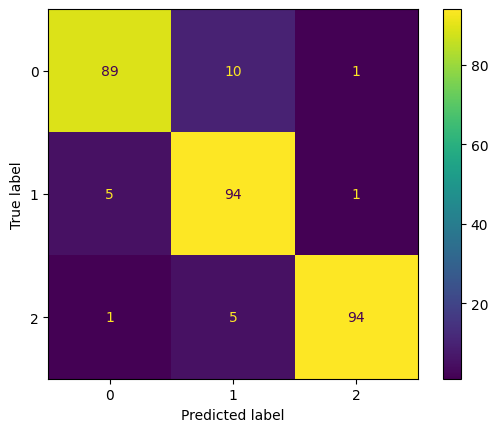

In [3]:
sk_model = LogisticRegression(C=2.0, max_iter=3000, random_state=SEED)
sk_model.fit(X_train, y_train)
p_sk = sk_model.predict_proba(X_test)
y_pred_sk = sk_model.predict(X_test)
print("scikit-learn accuracy:", accuracy_score(y_test, y_pred_sk))
print("scikit-learn log loss:", log_loss(y_test, p_sk))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_sk)
plt.show()
assert np.allclose(p_scratch.sum(axis=1), 1.0, atol=1e-10)
assert np.isfinite(p_scratch).all()
assert accuracy_score(y_test, y_pred_scratch) > 0.6


## 7. Hyperparameters and best practices

- `learning_rate`: too large can diverge; too small is slow. Inspect the loss curve.
- `epochs`: upper bound on full-batch updates; use a validation set for early stopping.
- `l2`: controls weight shrinkage. Tune without using the final test set.
- Standardize features using training data only.
- Evaluate per-class precision/recall and calibration when probabilities matter; accuracy alone can hide class imbalance.
- Use class weights or resampling carefully when appropriate.
- Softmax assumes mutually exclusive classes; use independent sigmoid outputs for genuinely multilabel targets.

## 8. Complexity and scaling

For n training examples, d features, K classes and T gradient steps, dense full-batch training costs $O(TndK)$. Batch inference for m observations costs $O(mdK)$; model storage is $O(dK)$. Full-batch gradient descent stores the data $O(nd)$ and probabilities $O(nK)$.

For millions of observations, use minibatch SGD or a library solver designed for large data; use sparse matrices for sparse inputs. GPU acceleration is promising for dense matrix multiplication, but benchmark the full pipeline including data transfer.

## 9. Optional PyTorch GPU implementation

The following is an independent tensor implementation. It runs on CUDA if available, otherwise reports that the GPU path was skipped.

In [4]:
try:
    import torch
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    Xt = torch.as_tensor(X_train, dtype=torch.float32, device=device)
    yt = torch.as_tensor(y_train, dtype=torch.long, device=device)
    k = int(np.max(y_train)) + 1
    Wt = torch.zeros((Xt.shape[1], k), device=device, requires_grad=True)
    bt = torch.zeros(k, device=device, requires_grad=True)
    opt = torch.optim.SGD([Wt, bt], lr=0.15)
    for _ in range(400):
        opt.zero_grad()
        logits = Xt @ Wt + bt
        loss = torch.nn.functional.cross_entropy(logits, yt) + 0.005 * (Wt*Wt).sum()/2
        loss.backward()
        opt.step()
    print("PyTorch device:", device)
    print("PyTorch test accuracy:", accuracy_score(y_test, (torch.as_tensor(X_test, dtype=torch.float32, device=device) @ Wt + bt).argmax(1).cpu().numpy()))
except ImportError:
    print("PyTorch is optional and is not installed.")


PyTorch device: cpu
PyTorch test accuracy: 0.9266666666666666


## 10. Correctness tests and synthesis

The softmax probabilities sum to one, cross-entropy measures the surprise of the observed labels, and gradient descent adjusts class scores to reduce that surprise. The result is a linear classifier with probabilistic outputs. The objective is convex, but evaluation on held-out data remains necessary to assess generalization.

In [5]:
assert np.isfinite(losses).all()
assert losses[-1] < losses[0]
assert np.all((y_pred_scratch >= 0) & (y_pred_scratch < n_classes))
try:
    fit_softmax_gd(np.array([1, 2, 3]), np.array([0, 1, 0]))
except ValueError:
    pass
else:
    raise AssertionError("Expected invalid X dimensionality to raise")
print("All softmax regression checks passed.")


All softmax regression checks passed.
